In [43]:
#Week 8 Assignment PBrown


# IS 362 - Week 8 Assignment

For this assignment, I am working with the Auto-MPG dataset. The column names are sourced directly from the dataset description file `auto-mpg.names`. I will be loading the data, cleaning up missing horsepower values, and visualizing relationships between variables like cylinders, weight, horsepower, and gas mileage.

Dataset citation and DOI reference:
Auto MPG. (1993). UCI Machine Learning Repository. https://doi.org/10.24432/C5859H

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean style for our plots
sns.set_theme(style="whitegrid")

## Loading the dataset
I'm reading the raw dataset directly from the UCI repository link. Since the columns are separated by arbitrary whitespace and there is no header in the raw file, I used the `names` parameter to apply the column labels defined in the `auto-mpg.names` documentation file.

In [45]:
columns = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year", "origin", "car_name"]
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

# Load dataset using whitespace separator
cars = pd.read_csv(url, sep=r"\s+", names=columns)
cars.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [46]:
print("Rows and columns:", cars.shape)

cars.info()

Rows and columns: (398, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [47]:
cars.describe()

,mpg,cylinders,displacement,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


## Data Cleaning Decisions

I replaced the missing horsepower values with NaN instead of zero because a missing measurement does not mean the car has zero horsepower. Using zero would add a value that was not actually recorded and could affect the results. After replacing the question marks, I converted the horsepower column to numeric data.

I also mapped the numeric values in the origin column to their corresponding country/region names to follow the assignment instructions.

In [48]:
# Horsepower has some missing values marked as '?'
print("Unknown horsepower count:", (cars["horsepower"] == "?").sum())

# Replace and convert to float
cars["horsepower"] = pd.to_numeric(cars["horsepower"].replace("?", float("nan")))
print("Null values after fix:", cars["horsepower"].isna().sum())

Unknown horsepower count: 6
Null values after fix: 6


In [49]:
origin_labels = {
    1: "USA",
    2: "Asia",
    3: "Europe"
}

cars["origin"] = cars["origin"].map(origin_labels)

cars["origin"].value_counts()

,count
origin,
USA,249
Europe,79
Asia,70


## Creating the Visualizations

cylinders
3      4
4    204
5      3
6     84
8    103
Name: count, dtype: int64


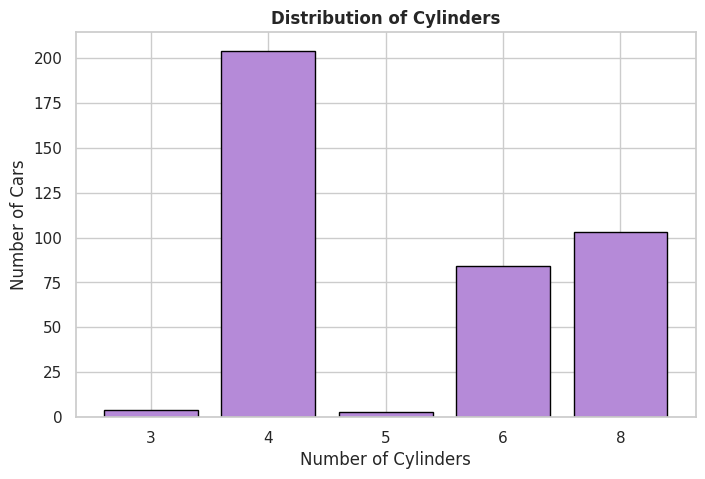

In [50]:
# get counts for each cylinder type
cylinder_counts = cars['cylinders'].value_counts().sort_index()
print(cylinder_counts)

# quick bar plot of the distribution using our custom purple theme color
plt.figure(figsize=(8, 5))
plt.bar(cylinder_counts.index.astype(str), cylinder_counts.values, color='#B58AD8', edgecolor='black')
plt.title('Distribution of Cylinders')
plt.xlabel('Number of Cylinders')
plt.ylabel('Number of Cars')
plt.show()

### Cylinder Distribution

I noticed that cars with 4, 6, and 8 cylinders were more common in this dataset than cars with 3 or 5 cylinders. Four-cylinder cars had the highest count at 204, followed by 103 eight-cylinder cars and 84 six-cylinder cars. There were only 4 three-cylinder cars and 3 five-cylinder cars.

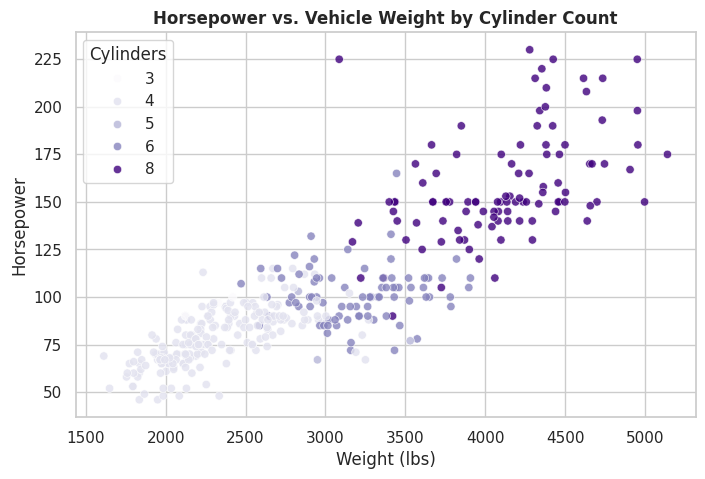

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

# Scatter plot of horsepower vs weight, color-coded by cylinder groups
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=cars,
    x="weight",
    y="horsepower",
    hue="cylinders",
    palette="Purples",
    alpha=0.8
)
plt.title("Horsepower vs. Vehicle Weight by Cylinder Count")
plt.xlabel("Weight (lbs)")
plt.ylabel("Horsepower")
plt.legend(title="Cylinders")
plt.show()

### Horsepower, Weight, and Cylinder Count

I noticed that heavier cars in this dataset generally had higher horsepower. I chose to color the points by the number of cylinders so I could see where each group fell in relation to weight and horsepower.

The eight-cylinder vehicles were generally clustered in the upper right, where both weight and horsepower were higher. This suggests an association among these variables, but the graph shows correlation rather than proving causation. The six cars with missing horsepower measurements are not included in this plot.

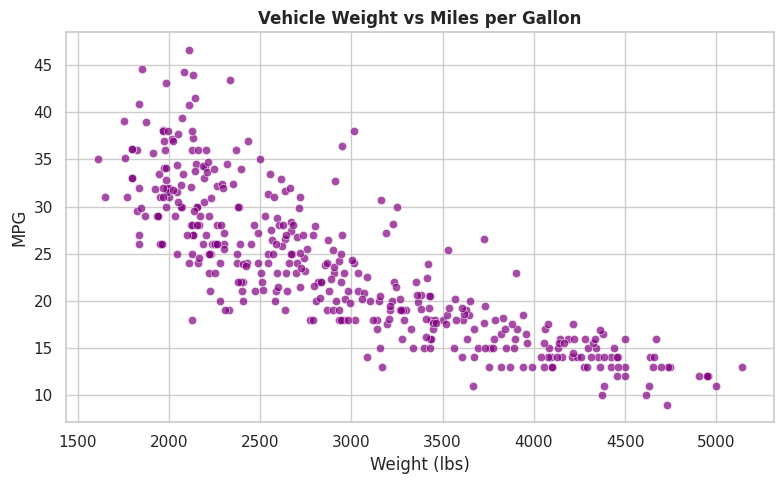

In [52]:
# Compare vehicle weight and fuel efficiency
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=cars,
    x="weight",
    y="mpg",
    color="purple",
    alpha=0.7
)

plt.title("Vehicle Weight vs Miles per Gallon")
plt.xlabel("Weight (lbs)")
plt.ylabel("MPG")
plt.tight_layout()
plt.show()

### 3. My Question: Is there a relationship between vehicle weight and fuel efficiency (MPG)?

**My observation and thoughts:**
Based on the scatter plot above, we can observe a general downward trend in fuel efficiency as vehicle weight increases.

Typically, lighter cars under 2,500 lbs show a strong tendency to achieve higher gas mileage, often exceeding 30 MPG with several exceptions reaching up into the 40s. Conversely, the heavy vehicles over 4,000 lbs consistently remain on the lower end of the efficiency spectrum, generally concentrated below 20 MPG.

While weight appears heavily associated with fuel economy, this single scatter plot shows correlation rather than proving direct physical causation, since heavier cars also systematically differ in other aspects like engine design.